### Question 1:
Scikit learn comes with the pre-loaded dataset, load the digits dataset from that collection and write a helper function to plot the image using matplotlib.

[Hint: Explore datasets module from scikit learn]

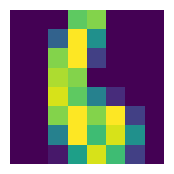

In [60]:
from sklearn.datasets import load_digits
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

digits = load_digits()

def load_image(i:int):
  plt.figure(figsize=(2, 2))
  plt.axis('off')
  plt.imshow(digits.images[i])
  plt.show()

load_image(6)

### Question 2:
Make a train-test split with 20% of the data set aside for testing. Fit a logistic regression model and observe the accuracy.

In [64]:
df = pd.DataFrame(digits.data)
df['target'] = digits.target
df.head()

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df.drop('target', axis='columns'), df.target, test_size=0.2)

from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=500)
model.fit(X_train, y_train)

model.score(X_test, y_test)

from sklearn.metrics import accuracy_score
y_pred = model.predict(X_test)
round(accuracy_score(y_test, y_pred)*100, 2)

95.83

### Question 3:
Using scikit learn perform a PCA transformation such that the transformed dataset can explain 95% of the variance in the original dataset. Find out the number of components in the projected subspace.

[Hint: Refer to decomposition module of scikit learn]

In [65]:
from sklearn.decomposition import PCA
pca = PCA(n_components=0.95)
X_reduced = pca.fit_transform(df.drop('target', axis='columns'))
X_reduced.shape

(1797, 29)

### Question 4:
Transform the dataset and fit a logistic regression and observe the accuracy. Compare it with the previous model and comment on the accuracy.

[Hint: Project both the train and test samples to the new subspace]

In [71]:
new_df = pd.concat([pd.DataFrame(X_reduced), df.target], axis=1)
new_X = new_df.drop('target', axis='columns')
new_y = new_df.target

new_X_train, new_X_test, new_y_train, new_y_test = train_test_split(new_X, new_y, test_size=0.4)

new_model = LogisticRegression(max_iter=500)
new_model.fit(new_X_train, new_y_train)

new_model.score(new_X_test, new_y_test)*100

new_y_pred = new_model.predict(new_X_test)
round(accuracy_score(new_y_test, new_y_pred)*100, 2)

95.97

### Question 5:
Compute the confusion matrix and count the number of instances that have gone wrong. For each wrong sample, plot the digit along with the predicted and original label.

[[67  0  0  0  0  0  0  0  0  0]
 [ 0 59  0  0  0  0  1  0  0  0]
 [ 0  1 75  0  0  0  0  0  0  0]
 [ 0  0  1 60  0  1  0  0  4  0]
 [ 1  0  0  0 60  0  0  0  0  0]
 [ 1  1  0  0  1 72  0  0  0  2]
 [ 0  1  0  0  0  1 63  0  1  0]
 [ 0  0  0  0  0  0  0 79  2  0]
 [ 0  2  0  0  0  0  0  0 80  1]
 [ 0  1  0  0  0  1  0  1  4 75]]


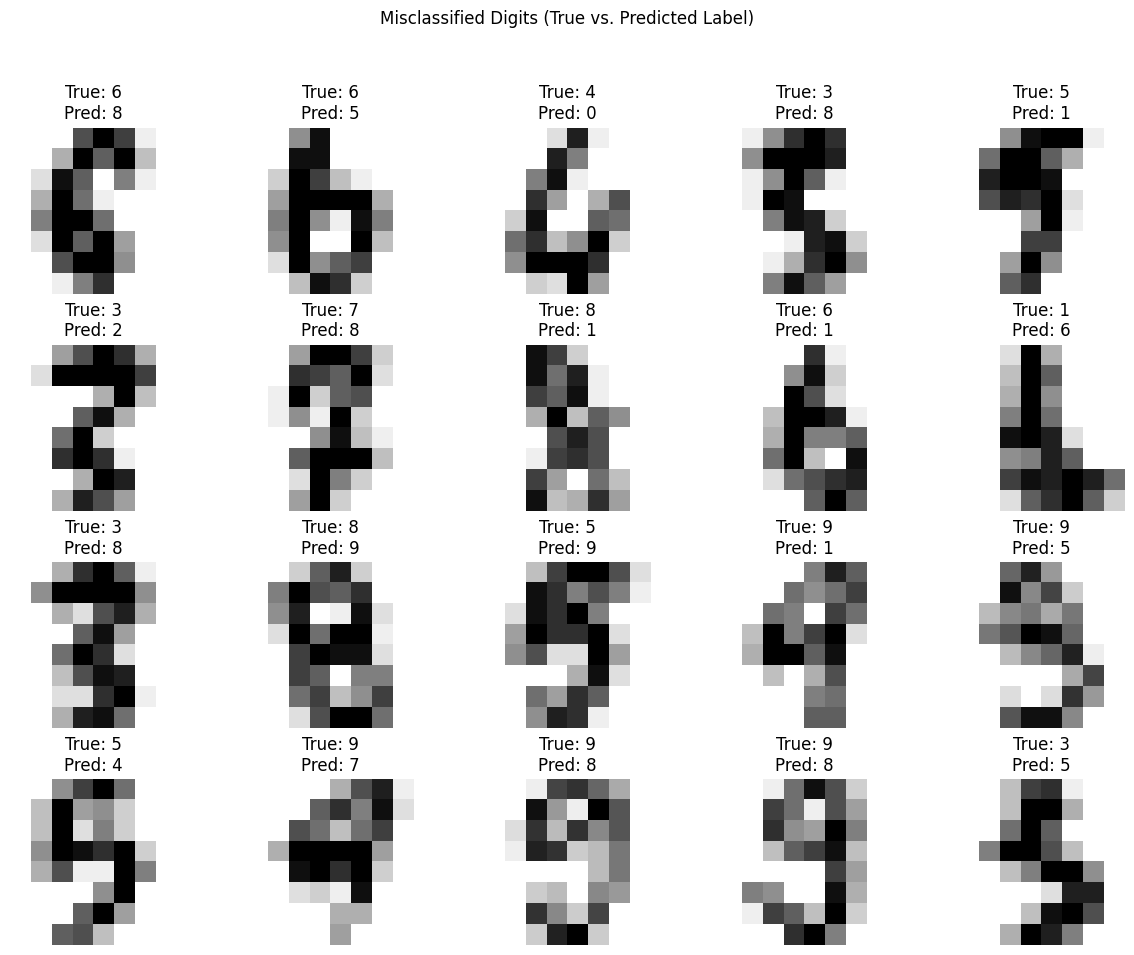

In [87]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(new_y_test, new_y_pred)
print(cm)

wrong_predictions_indices = np.where(new_y_test != new_y_pred)[0]
num_wrong = len(wrong_predictions_indices)

plt.figure(figsize=(12, 10))
for plot_idx, wrong_idx in enumerate(wrong_predictions_indices[:20]):
    original_image_index = new_y_test.index[wrong_idx]
    plt.subplot(4, 5, plot_idx + 1)
    plt.axis('off')
    plt.imshow(digits.images[original_image_index], cmap=plt.cm.gray_r)
    plt.title(f"True: {digits.target[original_image_index]}\nPred: {new_y_pred[wrong_idx]}")
plt.suptitle('Misclassified Digits (True vs. Predicted Label)')
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()